# 🧠 Los 9 Modelos de Machine Learning que Usa Tu Empresa
### Notebook de acompañamiento del vídeo — pruébalos tú mismo, en 3 líneas de código cada uno

Este Colab acompaña al vídeo *"Todos los modelos de Machine Learning que usa tu empresa explicados simple" del canal de youtube datascience4business*.

Vamos a construir una **empresa ficticia** (una tienda online con clientes, compras y reseñas) y vamos a aplicarle, uno detrás de otro, los 9 modelos del vídeo — sobre **los mismos clientes** de principio a fin.

---

## ▶️ Cómo usar este Colab (30 segundos)

1. Verás bloques de código como el de abajo. Dale clic al botón **▶** de la izquierda para ejecutarlo — no hace falta que entiendas el código.
2. Si te sale un aviso de *"no verificado por Google"*, es normal — dale a **"Ejecutar de todos modos"**.
3. Ve bajando y pulsando ▶ en cada bloque, en orden. Cada uno tarda unos segundos.

**¿No quieres ir celda a celda?** Ve a `Entorno de ejecución → Ejecutar todas`, y espera un par de minutos a que termine solo.

No necesitas instalar nada. Todo corre en la nube, en tu propia cuenta de Google

---

In [ ]:
# Instalamos/actualizamos las librerías que vamos a usar (unos segundos)
!pip install -q -U scikit-learn xgboost lightgbm ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.3/217.3 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 47.0 MB/s eta 0:00:00


## 🏪 Preparamos el escenario

Nuestra empresa ficticia es **NubeShop**, una tienda online con clientes recurrentes. Generamos un dataset sintético de 2.000 clientes — con su gasto, su frecuencia de compra, si han tenido alguna incidencia de soporte, y hasta la última reseña que dejaron.

Este dataset se genera aquí mismo con código, no tienes que cargar tú ningún dataset.

Y vamos a seguir a un cliente en particular — nuestro **Cliente Estrella** — a través de los 9 modelos, para ver qué dice cada uno sobre él.

Este código parece complicado, pero no es necesario que lo entiendas porque es solo la parte de crear los datos.

En una situación real ya tendrías datos y solo tendrías que importarlos que es mucho más sencillo.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
np.set_printoptions(suppress=True)


def generar_dataset(n=2000, seed=42):
    rng = np.random.default_rng(seed)

    edad = rng.normal(40, 12, n).clip(18, 75).round().astype(int)
    antiguedad_meses = rng.integers(1, 61, n)
    gasto_base = rng.gamma(shape=4.0, scale=35, size=n) + 20
    num_compras_mes = rng.poisson(lam=(gasto_base / 60)).clip(0, 20)
    aperturas_emails = rng.poisson(lam=3.2, size=n).clip(0, 15)
    dias_desde_ultima_compra = rng.exponential(scale=18, size=n).clip(0, 180).round().astype(int)
    incidencia_soporte = rng.binomial(1, 0.12, n)

    z_churn = (
        -0.8
        + 0.022 * dias_desde_ultima_compra
        - 0.15 * aperturas_emails
        - 0.012 * antiguedad_meses
        + 0.70 * incidencia_soporte
        - 0.003 * gasto_base
    )
    p_churn = 1 / (1 + np.exp(-z_churn))
    churn = rng.binomial(1, p_churn)

    # Relación deliberadamente NO lineal: umbral de desconexión + bonus a clientes
    # frecuentes de alto gasto + forma de U invertida en antigüedad.
    # Una regresión lineal no puede capturar bien estos efectos; un modelo de árboles sí.
    factor = 0.92 + 0.002 * antiguedad_meses - 0.35 * churn
    factor = factor - 0.28 * (dias_desde_ultima_compra > 60)
    factor = factor + 0.18 * ((num_compras_mes >= 5) & (gasto_base > 150))
    factor = factor - 0.00035 * (antiguedad_meses - 28) ** 2
    ruido = rng.normal(0, 10, n)
    gasto_mensual_siguiente = (gasto_base * factor + ruido).clip(0, None).round(2)

    z_camp = (
        -1.4
        + 0.012 * gasto_base
        + 0.15 * num_compras_mes
        + 0.01 * antiguedad_meses
        - 0.02 * dias_desde_ultima_compra
    )
    p_camp = 1 / (1 + np.exp(-z_camp))
    respondio_campana = rng.binomial(1, p_camp)

    categorias = np.array(["Electrónica", "Moda", "Hogar", "Deporte", "Belleza"])
    pesos_por_edad = np.stack([
        np.clip(0.35 - 0.004 * (edad - 25), 0.05, 0.6),
        np.full(n, 0.22),
        np.clip(0.15 + 0.004 * (edad - 25), 0.1, 0.4),
        np.full(n, 0.18),
        np.full(n, 0.15),
    ], axis=1)
    pesos_por_edad = pesos_por_edad / pesos_por_edad.sum(axis=1, keepdims=True)
    categoria_favorita = np.array([
        rng.choice(categorias, p=pesos_por_edad[i]) for i in range(n)
    ])

    return pd.DataFrame({
        "cliente_id": np.arange(1, n + 1),
        "edad": edad,
        "antiguedad_meses": antiguedad_meses,
        "gasto_mensual_actual": gasto_base.round(2),
        "num_compras_mes": num_compras_mes,
        "dias_desde_ultima_compra": dias_desde_ultima_compra,
        "aperturas_emails_mes": aperturas_emails,
        "incidencia_soporte": incidencia_soporte,
        "categoria_favorita": categoria_favorita,
        "churn": churn,
        "gasto_mensual_siguiente": gasto_mensual_siguiente,
        "respondio_campana": respondio_campana,
    })


def generar_resenas(n=2000, seed=7):
    rng = np.random.default_rng(seed)
    positivas = [
        "muy contento con el servicio", "todo llegó a tiempo y en buen estado",
        "excelente atención al cliente", "resolvieron mi duda muy rápido",
        "el producto superó mis expectativas", "envío rápido y sin problemas",
        "la aplicación es muy fácil de usar", "gran relación calidad precio",
        "el equipo de soporte fue muy amable", "todo tal como se describía",
        "volveré a comprar sin duda", "una experiencia estupenda de principio a fin",
    ]
    negativas = [
        "el pedido llegó tarde", "muy decepcionado con la calidad",
        "el servicio de atención no responde", "nadie me ayudó a resolver el problema",
        "la aplicación se bloquea constantemente", "no pienso volver a comprar aquí",
        "el producto llegó dañado", "cobraron de más sin explicación",
        "muy mala experiencia en general", "el soporte tardó días en contestar",
        "una experiencia bastante frustrante", "el proceso de devolución es lentísimo",
    ]
    textos, etiquetas = [], []
    for _ in range(n):
        es_positiva = rng.random() < 0.5
        banco = positivas if es_positiva else negativas
        frases = rng.choice(banco, size=rng.integers(1, 3), replace=False)
        if rng.random() < 0.06:
            frases = np.append(frases, rng.choice(negativas if es_positiva else positivas, size=1))
        texto = ". ".join(f.capitalize() for f in frases) + "."
        textos.append(texto)
        etiquetas.append(1 if es_positiva else 0)
    return pd.DataFrame({"resena_texto": textos, "sentimiento_positivo": etiquetas})


def cliente_estrella():
    # Cliente ficticio que NO forma parte del entrenamiento — solo predecimos sobre él.
    return pd.DataFrame([{
        "cliente_id": 99999,
        "edad": 34,
        "antiguedad_meses": 14,
        "gasto_mensual_actual": 145.0,
        "num_compras_mes": 2,
        "dias_desde_ultima_compra": 46,
        "aperturas_emails_mes": 1,
        "incidencia_soporte": 1,
    }])


def ficha(titulo, lineas):
    print("=" * 58)
    print(titulo)
    print("=" * 58)
    for l in lineas:
        print(" •", l)
    print()


df = generar_dataset()
resenas = generar_resenas()
est = cliente_estrella()

print(f"Dataset generado: {len(df):,} clientes de NubeShop\n")
df.head()

Dataset generado: 2,000 clientes de NubeShop



,cliente_id,edad,antiguedad_meses,gasto_mensual_actual,num_compras_mes,dias_desde_ultima_compra,aperturas_emails_mes,incidencia_soporte,categoria_favorita,churn,gasto_mensual_siguiente,respondio_campana
0,1,44,45,77.67,2,8,4,0,Moda,0,72.90,1
1,2,28,3,140.13,3,19,7,0,Belleza,0,99.75,1
2,3,49,22,372.39,4,6,2,0,Electrónica,0,358.02,1
3,4,51,27,282.25,4,9,1,0,Deporte,0,264.94,1
4,5,18,58,166.51,2,4,1,0,Hogar,1,77.36,1


In [ ]:
ficha("👤 NUESTRO CLIENTE ESTRELLA", [
    f"ID: {est.cliente_id.iloc[0]}",
    f"Edad: {est.edad.iloc[0]} años",
    f"Cliente desde hace: {est.antiguedad_meses.iloc[0]} meses",
    f"Gasto mensual actual: {est.gasto_mensual_actual.iloc[0]}€",
    f"Compras el último mes: {est.num_compras_mes.iloc[0]}",
    f"Días desde su última compra: {est.dias_desde_ultima_compra.iloc[0]}",
    f"Emails abiertos el último mes: {est.aperturas_emails_mes.iloc[0]}",
    f"¿Tuvo una incidencia de soporte?: {'Sí' if est.incidencia_soporte.iloc[0] else 'No'}",
])
print("Vamos a pasar a este cliente por los 9 modelos y ver qué dice cada uno de él.")

👤 NUESTRO CLIENTE ESTRELLA
 • ID: 99999
 • Edad: 34 años
 • Cliente desde hace: 14 meses
 • Gasto mensual actual: 145.0€
 • Compras el último mes: 2
 • Días desde su última compra: 46
 • Emails abiertos el último mes: 1
 • ¿Tuvo una incidencia de soporte?: Sí

Vamos a pasar a este cliente por los 9 modelos y ver qué dice cada uno de él.


A partir de aquí comienza el código de cada algoritmo.

El objetivo es que interiorices la estructura del análisis.

Si te fijas, independientemente del algoritmo concreto, con scikit learn casi siempre se sigue la misma estructura:

*   Importar el algoritmo a usar
*   Crear una instancia de ese algoritmo en una variable
*   Entrenar con fit
*   Predecir con predict o predict_proba

Obviamente esto es solo el esqueleto para que te empieces a familiarizar.

Si quieres dar un paso más y hacer gratis tu priemer curso de Data Science te puedes apuntar a www.tuprimerasemana.com



---
## 1️⃣ Regresión Lineal — "¿Cuánto va a gastar?"

Predice un **número**: el gasto del cliente el mes que viene, a partir de su gasto actual y su antigüedad.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

feats_lin = ["gasto_mensual_actual", "antiguedad_meses"]
X_train, X_test, y_train, y_test = train_test_split(
    df[feats_lin], df["gasto_mensual_siguiente"], test_size=0.2, random_state=42
)

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

pred_lineal = modelo_lineal.predict(est[feats_lin])[0]

ficha("📈 REGRESIÓN LINEAL", [
    f"Precisión del modelo (R²) sobre datos que nunca ha visto: {modelo_lineal.score(X_test, y_test):.2f}",
    f"Predicción de gasto el mes que viene para nuestro cliente estrella: {pred_lineal:.2f}€",
])

📈 REGRESIÓN LINEAL
 • Precisión del modelo (R²) sobre datos que nunca ha visto: 0.75
 • Predicción de gasto el mes que viene para nuestro cliente estrella: 119.83€



---
## 2️⃣ Regresión Logística — "¿Se va a dar de baja?"

Predice una **probabilidad entre 0 y 1**: la probabilidad de que este cliente cancele.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

feats_log = ["dias_desde_ultima_compra", "aperturas_emails_mes", "antiguedad_meses",
             "incidencia_soporte", "gasto_mensual_actual"]
X_train, X_test, y_train, y_test = train_test_split(
    df[feats_log], df["churn"], test_size=0.2, random_state=42, stratify=df["churn"]
)

modelo_logistico = LogisticRegression()
modelo_logistico.fit(X_train, y_train)

auc = roc_auc_score(y_test, modelo_logistico.predict_proba(X_test)[:, 1])
p_baja = modelo_logistico.predict_proba(est[feats_log])[0, 1]

ficha("🎯 REGRESIÓN LOGÍSTICA", [
    f"Capacidad del modelo para distinguir quién se va y quién se queda (AUC): {auc:.2f}",
    f"Probabilidad de baja de nuestro cliente estrella: {p_baja*100:.1f}%",
    "⚠️ Con más de un 50%, este cliente entraría en la lista de contacto prioritario de retención.",
])

🎯 REGRESIÓN LOGÍSTICA
 • Capacidad del modelo para distinguir quién se va y quién se queda (AUC): 0.71
 • Probabilidad de baja de nuestro cliente estrella: 60.3%
 • ⚠️ Con más de un 50%, este cliente entraría en la lista de contacto prioritario de retención.



---
## 3️⃣ KNN (K Vecinos Más Cercanos) — "¿Qué le recomendamos?"

Busca los clientes más parecidos a él, y mira qué categoría de producto compran más.

👉 **Prueba a mover el slider** y observa cómo cambia la recomendación según cuántos "vecinos" mires.

In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from ipywidgets import interact, IntSlider

feats_knn = ["gasto_mensual_actual", "num_compras_mes", "antiguedad_meses", "dias_desde_ultima_compra"]

scaler_knn = StandardScaler()
X_scaled = scaler_knn.fit_transform(df[feats_knn])
est_scaled = scaler_knn.transform(est[feats_knn])


def recomendar(k=5):
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X_scaled)
    _, idx = nn.kneighbors(est_scaled)
    vecinos = df.iloc[idx[0]]
    conteo = vecinos["categoria_favorita"].value_counts()
    ficha(f"🧭 KNN (K={k})", [
        f"Categoría más comprada entre sus {k} vecinos más parecidos: {conteo.idxmax()}",
        f"Desglose completo: {dict(conteo)}",
    ])


interact(recomendar, k=IntSlider(min=3, max=50, step=1, value=5, description="K vecinos"));

interactive(children=(IntSlider(value=5, description='K vecinos', max=50, min=3), Output()), _dom_classes=('wi…

---
## 4️⃣ Naive Bayes — "¿Qué opinan de nosotros?"

Aquí cambiamos de tipo de dato: en vez de números, **texto**. Clasificamos reseñas de clientes como positivas o negativas.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    resenas.resena_texto, resenas.sentimiento_positivo, test_size=0.2, random_state=42
)

vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(X_train_txt)
X_test = vectorizer.transform(X_test_txt)

modelo_nb = MultinomialNB()
modelo_nb.fit(X_train, y_train)
acc = accuracy_score(y_test, modelo_nb.predict(X_test))

# Probamos con una reseña nueva, escrita a mano
nueva_resena = ["El pedido llegó tarde y el soporte no contesta a mis mensajes"]
proba = modelo_nb.predict_proba(vectorizer.transform(nueva_resena))[0]

ficha("💬 NAIVE BAYES", [
    f"Precisión del modelo clasificando reseñas que nunca ha visto: {acc*100:.1f}%",
    f'Reseña de prueba: "{nueva_resena[0]}"',
    f"Probabilidad de que sea positiva: {proba[1]*100:.1f}% | negativa: {proba[0]*100:.1f}%",
])
print("✏️  Cambia el texto de 'nueva_resena' arriba y vuelve a ejecutar la celda para probar tus propios ejemplos.")

💬 NAIVE BAYES
 • Precisión del modelo clasificando reseñas que nunca ha visto: 98.8%
 • Reseña de prueba: "El pedido llegó tarde y el soporte no contesta a mis mensajes"
 • Probabilidad de que sea positiva: 0.1% | negativa: 99.9%

✏️  Cambia el texto de 'nueva_resena' arriba y vuelve a ejecutar la celda para probar tus propios ejemplos.


---
## 5️⃣ K-means — "¿En qué grupo de clientes está?"

Aquí no hay ninguna respuesta correcta que darle al modelo — el propio modelo encuentra los grupos.

👉 **Mueve el slider** del número de grupos y observa cómo cambian los perfiles y en qué grupo cae nuestro cliente.

In [ ]:
from sklearn.cluster import KMeans

feats_km = ["gasto_mensual_actual", "num_compras_mes", "dias_desde_ultima_compra", "antiguedad_meses"]
scaler_km = StandardScaler()
X_scaled_km = scaler_km.fit_transform(df[feats_km])
est_scaled_km = scaler_km.transform(est[feats_km])


def segmentar(k=4):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_scaled_km)
    df_tmp = df.copy()
    df_tmp["grupo"] = etiquetas
    resumen = df_tmp.groupby("grupo")[feats_km].mean().round(1)
    grupo_estrella = km.predict(est_scaled_km)[0]

    print(f"--- {k} grupos encontrados por el modelo ---")
    display(resumen)
    print(f"\n👉 Nuestro cliente estrella cae en el grupo {grupo_estrella}\n")

    plt.figure(figsize=(6, 4))
    plt.scatter(df_tmp["antiguedad_meses"], df_tmp["gasto_mensual_actual"],
                c=df_tmp["grupo"], cmap="tab10", alpha=0.4, s=12)
    plt.scatter(est["antiguedad_meses"], est["gasto_mensual_actual"],
                c="black", marker="*", s=300, label="Cliente estrella")
    plt.xlabel("Antigüedad (meses)")
    plt.ylabel("Gasto mensual actual (€)")
    plt.title(f"Segmentación de clientes (K={k})")
    plt.legend()
    plt.show()


interact(segmentar, k=IntSlider(min=2, max=8, step=1, value=4, description="Nº grupos"));

interactive(children=(IntSlider(value=4, description='Nº grupos', max=8, min=2), Output()), _dom_classes=('wid…

---
## 6️⃣ Árbol de Decisión — "¿Le enviamos la campaña?"

El modelo más fácil de auditar: literalmente puedes ver las preguntas que se ha hecho.

Vemos también su **variante de regresión**: en vez de sí/no, un número (el ticket medio esperado).

🌳 ÁRBOL DE DECISIÓN
 • Precisión del modelo sobre datos que nunca ha visto: 65.5%
 • ¿Enviarle la campaña? NO (confianza: 55.3%)
 • Variante de regresión — ticket medio esperado: 141.35€



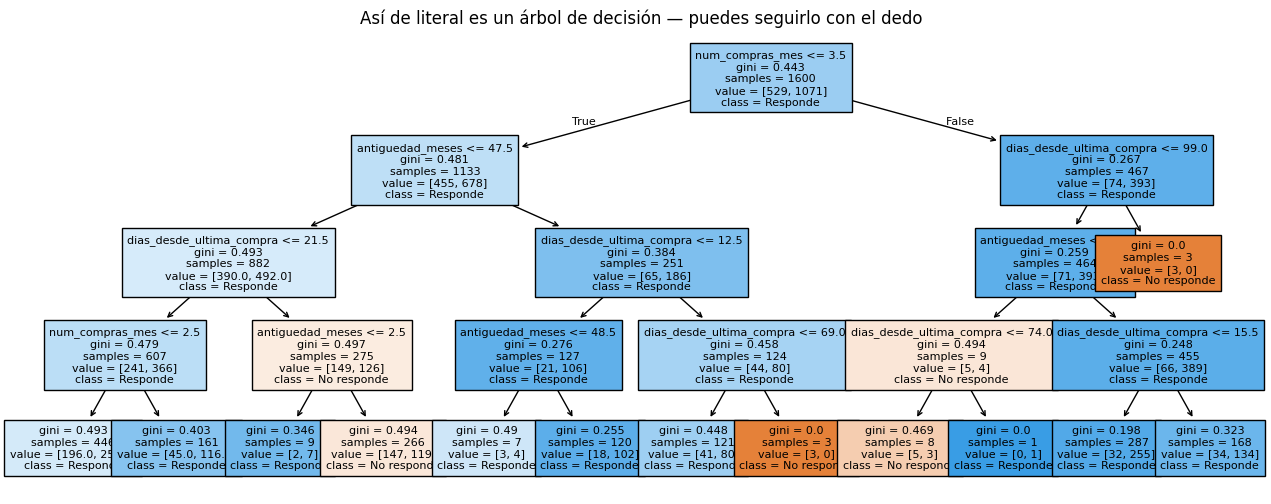

In [ ]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

feats_arbol = ["dias_desde_ultima_compra", "num_compras_mes", "antiguedad_meses"]
X_train, X_test, y_train, y_test = train_test_split(
    df[feats_arbol], df["respondio_campana"], test_size=0.2, random_state=42, stratify=df["respondio_campana"]
)

arbol_clasificacion = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol_clasificacion.fit(X_train, y_train)
acc_arbol = accuracy_score(y_test, arbol_clasificacion.predict(X_test))

pred_clase = arbol_clasificacion.predict(est[feats_arbol])[0]
proba_arbol = arbol_clasificacion.predict_proba(est[feats_arbol])[0]

# Variante de regresión: ticket medio esperado
arbol_regresion = DecisionTreeRegressor(max_depth=4, random_state=42)
arbol_regresion.fit(df[feats_arbol], df["gasto_mensual_actual"])
pred_ticket = arbol_regresion.predict(est[feats_arbol])[0]

ficha("🌳 ÁRBOL DE DECISIÓN", [
    f"Precisión del modelo sobre datos que nunca ha visto: {acc_arbol*100:.1f}%",
    f"¿Enviarle la campaña? {'SÍ' if pred_clase == 1 else 'NO'} (confianza: {max(proba_arbol)*100:.1f}%)",
    f"Variante de regresión — ticket medio esperado: {pred_ticket:.2f}€",
])

plt.figure(figsize=(16, 6))
plot_tree(arbol_clasificacion, feature_names=feats_arbol, class_names=["No responde", "Responde"],
          filled=True, fontsize=8)
plt.title("Así de literal es un árbol de decisión — puedes seguirlo con el dedo")
plt.show()

---
## 7️⃣ Random Forest — "No confíes en un solo árbol"

Vamos a entrenar 5 árboles individuales, cada uno con una muestra distinta de datos, y ver si se ponen de acuerdo sobre nuestro cliente. Luego comparamos con un bosque de 300 árboles votando juntos.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rng_local = np.random.default_rng(0)
predicciones_individuales = []
print("5 árboles individuales, cada uno entrenado con una muestra distinta:\n")
for i in range(5):
    idx = rng_local.choice(len(X_train), size=len(X_train), replace=True)
    Xb, yb = X_train.iloc[idx], y_train.iloc[idx]
    arbolito = DecisionTreeClassifier(max_depth=4, random_state=i)
    arbolito.fit(Xb, yb)
    p = arbolito.predict(est[feats_arbol])[0]
    predicciones_individuales.append(p)
    print(f"  Árbol {i+1}: {'SÍ enviar' if p == 1 else 'NO enviar'}")

n_si = predicciones_individuales.count(1)
print(f"\n👉 {n_si} de 5 árboles dicen 'sí', {5-n_si} dicen 'no' — así de inestable es un solo árbol.\n")

bosque = RandomForestClassifier(n_estimators=300, max_depth=4, random_state=42)
bosque.fit(X_train, y_train)
acc_bosque = accuracy_score(y_test, bosque.predict(X_test))
proba_bosque = bosque.predict_proba(est[feats_arbol])[0]

ficha("🌲🌲🌲 RANDOM FOREST (300 árboles)", [
    f"Precisión del modelo sobre datos que nunca ha visto: {acc_bosque*100:.1f}%",
    f"Probabilidad de que responda a la campaña, según el consenso del bosque: {proba_bosque[1]*100:.1f}%",
])

5 árboles individuales, cada uno entrenado con una muestra distinta:

  Árbol 1: NO enviar
  Árbol 2: NO enviar
  Árbol 3: NO enviar
  Árbol 4: NO enviar
  Árbol 5: SÍ enviar

👉 1 de 5 árboles dicen 'sí', 4 dicen 'no' — así de inestable es un solo árbol.

🌲🌲🌲 RANDOM FOREST (300 árboles)
 • Precisión del modelo sobre datos que nunca ha visto: 65.8%
 • Probabilidad de que responda a la campaña, según el consenso del bosque: 50.9%



---
## 8️⃣ XGBoost — "Cuando cada euro de error cuenta"

Volvemos a la pregunta del bloque 1 (¿cuánto va a gastar?), pero ahora con un modelo que corrige sus propios errores árbol tras árbol. Comparamos el error real frente a la regresión lineal.

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

feats_xgb = ["gasto_mensual_actual", "antiguedad_meses", "num_compras_mes",
             "dias_desde_ultima_compra", "aperturas_emails_mes", "incidencia_soporte"]
X_train, X_test, y_train, y_test = train_test_split(
    df[feats_xgb], df["gasto_mensual_siguiente"], test_size=0.2, random_state=42
)

# Regresión lineal, para comparar en igualdad de condiciones
lin_comparacion = LinearRegression().fit(X_train, y_train)
mae_lineal = mean_absolute_error(y_test, lin_comparacion.predict(X_test))

modelo_xgb = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)
modelo_xgb.fit(X_train, y_train)
mae_xgb = mean_absolute_error(y_test, modelo_xgb.predict(X_test))

pred_xgb = modelo_xgb.predict(est[feats_xgb])[0]
pred_lineal_comp = lin_comparacion.predict(est[feats_xgb])[0]

ficha("🚀 XGBOOST vs REGRESIÓN LINEAL", [
    f"Error medio (MAE) Regresión Lineal: {mae_lineal:.2f}€",
    f"Error medio (MAE) XGBoost:          {mae_xgb:.2f}€",
    f"Mejora de XGBoost: {(1 - mae_xgb/mae_lineal)*100:.1f}% menos error",
    f"Predicción regresión lineal para el cliente estrella: {pred_lineal_comp:.2f}€",
    f"Predicción XGBoost para el cliente estrella:          {pred_xgb:.2f}€",
])
print("La diferencia viene de relaciones que la regresión lineal no puede capturar")
print("(umbrales, combinaciones de variables) y que XGBoost sí detecta solo.")

🚀 XGBOOST vs REGRESIÓN LINEAL
 • Error medio (MAE) Regresión Lineal: 25.64€
 • Error medio (MAE) XGBoost:          19.08€
 • Mejora de XGBoost: 25.6% menos error
 • Predicción regresión lineal para el cliente estrella: 92.85€
 • Predicción XGBoost para el cliente estrella:          103.13€

La diferencia viene de relaciones que la regresión lineal no puede capturar
(umbrales, combinaciones de variables) y que XGBoost sí detecta solo.


---
## 9️⃣ LightGBM — "Cuando el volumen de datos se dispara"

Misma tarea que XGBoost, pero ahora con **300.000 clientes** en vez de 2.000, para poner a prueba la velocidad de cada uno. Los tiempos que verás son los de tu propia ejecución ahora mismo, no un número inventado.

In [ ]:
import time
from lightgbm import LGBMRegressor

print("Generando un dataset de 300.000 clientes para la prueba de velocidad...")
df_grande = generar_dataset(n=300_000, seed=123)
X_grande = df_grande[feats_xgb]
y_grande = df_grande["gasto_mensual_siguiente"]

t0 = time.time()
XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42).fit(X_grande, y_grande)
t_xgb = time.time() - t0

t0 = time.time()
LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1).fit(X_grande, y_grande)
t_lgbm = time.time() - t0

ficha("⚡ LIGHTGBM vs XGBOOST — 300.000 filas", [
    f"Tiempo de entrenamiento XGBoost:  {t_xgb:.2f} segundos",
    f"Tiempo de entrenamiento LightGBM: {t_lgbm:.2f} segundos",
])
if t_lgbm < t_xgb:
    print(f"En esta ejecución, LightGBM ha sido {t_xgb/t_lgbm:.2f}x más rápido.")
else:
    print(f"En esta ejecución, ambos han ido muy parejos ({t_xgb:.1f}s vs {t_lgbm:.1f}s).")
print("\nNota honesta: las versiones modernas de XGBoost han cerrado mucho la diferencia de velocidad.")
print("La ventaja real de LightGBM hoy se nota más en memoria y en reentrenamientos muy frecuentes con volúmenes aún mayores.")

Generando un dataset de 300.000 clientes para la prueba de velocidad...
⚡ LIGHTGBM vs XGBOOST — 300.000 filas
 • Tiempo de entrenamiento XGBoost:  4.77 segundos
 • Tiempo de entrenamiento LightGBM: 5.68 segundos

En esta ejecución, ambos han ido muy parejos (4.8s vs 5.7s).

Nota honesta: las versiones modernas de XGBoost han cerrado mucho la diferencia de velocidad.
La ventaja real de LightGBM hoy se nota más en memoria y en reentrenamientos muy frecuentes con volúmenes aún mayores.


---
## 🗂️ Cierre — La ficha completa de nuestro cliente, construida por los 9 modelos

No hay un modelo "mejor" en general — cada uno responde una pregunta de negocio distinta sobre el mismo cliente. Aquí tienes las 9 respuestas juntas.

In [ ]:
print("="*58)
print(f"FICHA COMPLETA — Cliente #{est.cliente_id.iloc[0]}")
print("="*58)
print(f" 1. Regresión Lineal    → gastará ~{pred_lineal:.0f}€ el próximo mes")
print(f" 2. Regresión Logística → {p_baja*100:.0f}% de probabilidad de baja")
print(f" 3. KNN                 → recomendarle productos de la categoría más vista por sus vecinos")
print(f" 4. Naive Bayes         → (aplicado a sus reseñas de texto, si las tuviera)")
print(f" 5. K-means             → pertenece a un grupo de comportamiento concreto (ver arriba)")
print(f" 6. Árbol de Decisión   → {'SÍ' if pred_clase == 1 else 'NO'} enviarle la campaña (ticket medio esperado: {pred_ticket:.0f}€)")
print(f" 7. Random Forest       → {proba_bosque[1]*100:.0f}% de probabilidad de respuesta (consenso de 300 árboles)")
print(f" 8. XGBoost             → gastará ~{pred_xgb:.0f}€ el próximo mes (predicción más precisa)")
print(f" 9. LightGBM            → mismo tipo de predicción que XGBoost, pensado para escalar a millones de clientes")
print("="*58)
print("\nCada modelo mira al mismo cliente desde un ángulo distinto.")
print("La pregunta correcta no es \'¿cuál es el mejor modelo?\', sino \'¿qué pregunta de negocio tengo?\'")

FICHA COMPLETA — Cliente #99999
 1. Regresión Lineal    → gastará ~120€ el próximo mes
 2. Regresión Logística → 60% de probabilidad de baja
 3. KNN                 → recomendarle productos de la categoría más vista por sus vecinos
 4. Naive Bayes         → (aplicado a sus reseñas de texto, si las tuviera)
 5. K-means             → pertenece a un grupo de comportamiento concreto (ver arriba)
 6. Árbol de Decisión   → NO enviarle la campaña (ticket medio esperado: 141€)
 7. Random Forest       → 51% de probabilidad de respuesta (consenso de 300 árboles)
 8. XGBoost             → gastará ~103€ el próximo mes (predicción más precisa)
 9. LightGBM            → mismo tipo de predicción que XGBoost, pensado para escalar a millones de clientes

Cada modelo mira al mismo cliente desde un ángulo distinto.
La pregunta correcta no es '¿cuál es el mejor modelo?', sino '¿qué pregunta de negocio tengo?'


---
## 🎬 ¿Y ahora qué?

Has ejecutado los 9 modelos del vídeo, sobre datos que se generan en el momento — puedes volver cuando quieras y ejecutarlo de nuevo, cambiar los números del cliente estrella, o tocar los sliders para ver cómo cambia cada resultado.

**Recuerda:** todos estos modelos trabajaban sobre datos en tabla. Cuando el dato es una imagen, un audio o texto sin estructurar de verdad, entramos en el terreno de las redes neuronales — que es, como te dije en el vídeo, el tema del próximo capítulo si lo pedís lo suficiente en comentarios 👀

Gracias por probar esto hasta el final — significa que de verdad quieres aplicar esto en tu empresa, no solo verlo en un vídeo.

RECUERDA. SI QUIERES CONTINUAR CON TU PRIMER CURSO DE DATA SCIENCE CON IA PUEDES APUNTARTE GRATIS EN www.tuprimerasemana.com

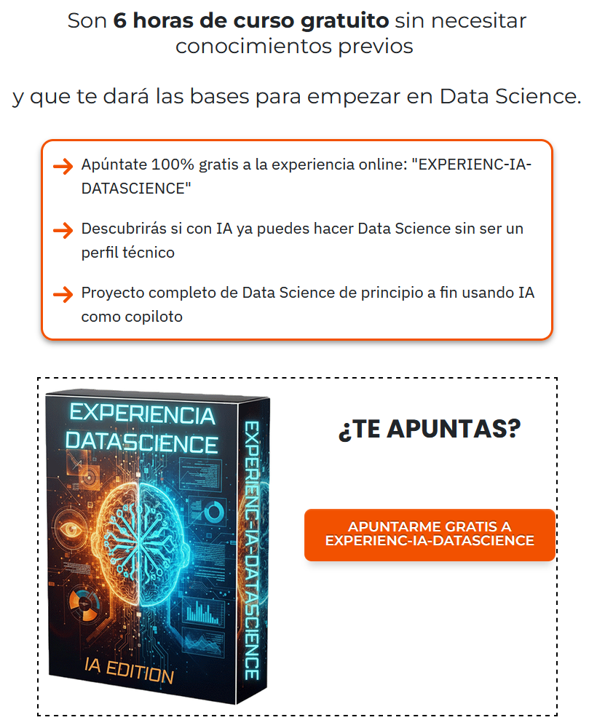 (www.tuprimerasemana.com)